In [1]:
import tensorflow as tf
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2

2025-10-11 07:39:11.093084: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
gpus = tf.config.list_physical_devices('GPU')
print("GPUs available to TensorFlow:", gpus)

# Detailed info (name, memory, etc.)
from tensorflow.python.client import device_lib
devices = device_lib.list_local_devices()
for d in devices:
    if d.device_type == "GPU":
        print(f"TensorFlow is using: {d.physical_device_desc}")

GPUs available to TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow is using: device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


I0000 00:00:1760148559.738804   19016 gpu_device.cc:2020] Created device /device:GPU:0 with 4149 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:
TRAIN_PATH = './dataset/train'
TEST_PATH = './dataset/test'

IMAGE_SIZE = [224, 224]

# Define batch size for training
BATCH_SIZE = 32

In [4]:
def rgb_to_od(im):
    """Convert RGB to Optical Density space."""
    im = im.astype(float)
    im[im == 0] = 1e-6 # Avoid log of zero
    return -np.log(im / 255.0)

def od_to_rgb(od):
    """Convert Optical Density back to RGB space."""
    od = np.exp(-od) * 255.0
    return od.clip(0, 255).astype(np.uint8)

def get_stain_vectors(od_image_flat):
    """Find stain vectors using Singular Value Decomposition (SVD)."""
    _, _, V = np.linalg.svd(od_image_flat, full_matrices=False)
    return V[0:2, :]

def normalize_stain(source_img, target_vectors):
    """Main function to normalize the stain of a source image."""
    source_od = rgb_to_od(source_img)
    source_od_flat = source_od.reshape((-1, 3))
    
    mask = np.sum(source_od_flat, axis=1) > 0.15
    source_od_flat_filtered = source_od_flat[mask]

    # If the image is too light (all pixels filtered out), return the original
    if len(source_od_flat_filtered) == 0:
        return source_img
        
    source_vectors = get_stain_vectors(source_od_flat_filtered)
    source_concentrations = np.dot(source_od_flat_filtered, source_vectors.T)
    
    # Check for instability in matrix inversion
    try:
        inv_product = np.linalg.inv(np.dot(target_vectors, source_vectors.T))
        transformed_concentrations = np.dot(source_concentrations, inv_product)
    except np.linalg.LinAlgError:
        # If inversion fails, return the original image
        return source_img
    
    final_od_flat_filtered = np.dot(transformed_concentrations, target_vectors)
    
    ### --- START: CORRECTED CODE --- ###
    # Create a flattened copy of the original OD image to modify
    final_od_flat = source_od_flat.copy() 
    
    # Place the normalized pixel values back into the flattened array using the mask
    final_od_flat[mask] = final_od_flat_filtered
    
    # Reshape the flattened array back to the original 3D image shape
    final_od = final_od_flat.reshape(source_od.shape)
    ### --- END: CORRECTED CODE --- ###
    
    final_rgb = od_to_rgb(final_od)
    
    return final_rgb

print("Stain normalization functions defined.")

Stain normalization functions defined.


In [5]:
def crop_or_pad_to_size(image, target_height=224, target_width=224):
    h, w, _ = image.shape
    if h > target_height or w > target_width:
        start_y = max(0, (h - target_height) // 2)
        start_x = max(0, (w - target_width) // 2)
        return image[start_y:start_y + target_height, start_x:start_x + target_width]
    if h < target_height or w < target_width:
        pad_y_top = (target_height - h) // 2
        pad_y_bottom = target_height - h - pad_y_top
        pad_x_left = (target_width - w) // 2
        pad_x_right = target_width - w - pad_x_left
        return cv2.copyMakeBorder(image, pad_y_top, pad_y_bottom, pad_x_left, pad_x_right, cv2.BORDER_CONSTANT, value=[0, 0, 0])
    return image

# --- NEW FUNCTION: Crops a square from inside the largest detected cell ---
def crop_to_largest_cell(image):
    """
    Finds the largest cell in an image, crops a square from its center,
    and resizes it to the target model input size (e.g., 224x224).
    """
    # Convert to grayscale and apply a blur to improve detection
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray_blurred = cv2.medianBlur(gray, 5)

    # Use HoughCircles to find cells. Note the new radius parameters
    # are set to find larger cells of interest, not just RBCs.
    circles = cv2.HoughCircles(gray_blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=40,
                               param1=60, param2=35, minRadius=30, maxRadius=100)

    if circles is not None:
        circles = np.round(circles[0, :]).astype("int")
        
        # Find the circle with the largest radius
        largest_circle = max(circles, key=lambda x: x[2])
        (x, y, r) = largest_circle
        
        # Calculate the side of the inscribed square
        # We use 0.7 * (2*r) to ensure the square is well within the circle
        side = int(1.4 * r)
        
        # Get the top-left corner of the square
        x1 = max(0, x - side // 2)
        y1 = max(0, y - side // 2)
        # Get the bottom-right corner
        x2 = min(image.shape[1], x + side // 2)
        y2 = min(image.shape[0], y + side // 2)
        
        # Crop the image to this square
        cell_crop = image[y1:y2, x1:x2]
        
        # If the crop is valid, resize and return it
        if cell_crop.shape[0] > 0 and cell_crop.shape[1] > 0:
            return cv2.resize(cell_crop, (IMAGE_SIZE[0], IMAGE_SIZE[1]), interpolation=cv2.INTER_AREA)

    # Fallback: If no cells are found, return a standard center crop
    return crop_or_pad_to_size(image)


def crop_to_largest_cell_contour(image):
    """
    Finds the largest cell based on color segmentation and contour detection,
    crops a square region around it, and resizes to 224x224.
    """
    # --- FIX: Use the correct OpenCV constant COLOR_RGB2HSV ---
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Define the color range for the purple/blue nuclei of the cells
    lower_purple = np.array([125, 40, 40])
    upper_purple = np.array([175, 255, 255])
    
    # Create a mask that isolates the cells
    mask = cv2.inRange(hsv, lower_purple, upper_purple)

    # Find contours (outlines) of the cells in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        # Find the contour with the largest area
        largest_contour = max(contours, key=cv2.contourArea)
        
        # Get the bounding box of the largest contour
        x, y, w, h = cv2.boundingRect(largest_contour)
        
        # Create a square crop around the cell for consistency
        center_x, center_y = x + w // 2, y + h // 2
        size = max(w, h) + 20 # Add 20 pixels padding
        
        x1 = max(0, center_x - size // 2)
        y1 = max(0, center_y - size // 2)
        x2 = min(image.shape[1], center_x + size // 2)
        y2 = min(image.shape[0], center_y + size // 2)
        
        cell_crop = image[y1:y2, x1:x2]
        
        if cell_crop.shape[0] > 0 and cell_crop.shape[1] > 0:
            return cv2.resize(cell_crop, (IMAGE_SIZE[0], IMAGE_SIZE[1]), interpolation=cv2.INTER_AREA)

    # Fallback: If no contours are found, take a simple center crop
    h, w, _ = image.shape
    start_y = max(0, (h - IMAGE_SIZE[0]) // 2)
    start_x = max(0, (w - IMAGE_SIZE[1]) // 2)
    return image[start_y:start_y + IMAGE_SIZE[0], start_x:start_x + IMAGE_SIZE[1]]

In [6]:
try:
    target_image_path = os.path.join(TRAIN_PATH, 'Healthy', os.listdir(os.path.join(TRAIN_PATH, 'Healthy'))[0])
    target_image_data = image.load_img(target_image_path)
    target_image_array = image.img_to_array(target_image_data)

    target_od = rgb_to_od(target_image_array)
    target_od_flat = target_od.reshape((-1, 3))
    mask_target = np.sum(target_od_flat, axis=1) > 0.15
    target_od_flat_filtered = target_od_flat[mask_target]
    TARGET_STAIN_VECTORS = get_stain_vectors(target_od_flat_filtered)
    print("Target stain vectors prepared successfully.")
except Exception as e:
    print(f"Error preparing target image: {e}")
    print("Please ensure the TRAIN_PATH is correct and the 'Healthy' directory is not empty.")
    TARGET_STAIN_VECTORS = None

Target stain vectors prepared successfully.


In [7]:
def custom_preprocessing(img_array):
    """
    Chains stain normalization, contour-based cell cropping, and MobileNetV2 preprocessing.
    ORDER: Stain -> Crop -> Model.
    """
    img_uint8 = img_array.astype(np.uint8)
    
    # 1. Apply Stain Normalization on the original image
    normalized_stain_img = normalize_stain(img_uint8, TARGET_STAIN_VECTORS)
    
    # 2. Apply the new and improved Contour-based Cropping function
    cropped_cell_img = crop_to_largest_cell_contour(normalized_stain_img)
    
    # 3. Apply MobileNetV2 Preprocessing as the final step
    final_processed_img = preprocess_input(cropped_cell_img.astype('float32'))
    
    return final_processed_img

print("Contour-based cropping and final preprocessing pipeline are ready.")

# Create ImageDataGenerator with our custom function and data augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=custom_preprocessing,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

test_datagen = ImageDataGenerator(
    preprocessing_function=custom_preprocessing
)

# Load data using the generators
training_set = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

validation_set = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_set = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_labels = list(training_set.class_indices.keys())
print("\nClass Labels:", class_labels)

Contour-based cropping and final preprocessing pipeline are ready.
Found 12000 images belonging to 5 classes.
Found 3000 images belonging to 5 classes.
Found 5000 images belonging to 5 classes.

Class Labels: ['ALL', 'AML', 'CLL', 'CML', 'Healthy']


Displaying the full preprocessing pipeline: Original -> Stain Normalized -> Cropped to Cell


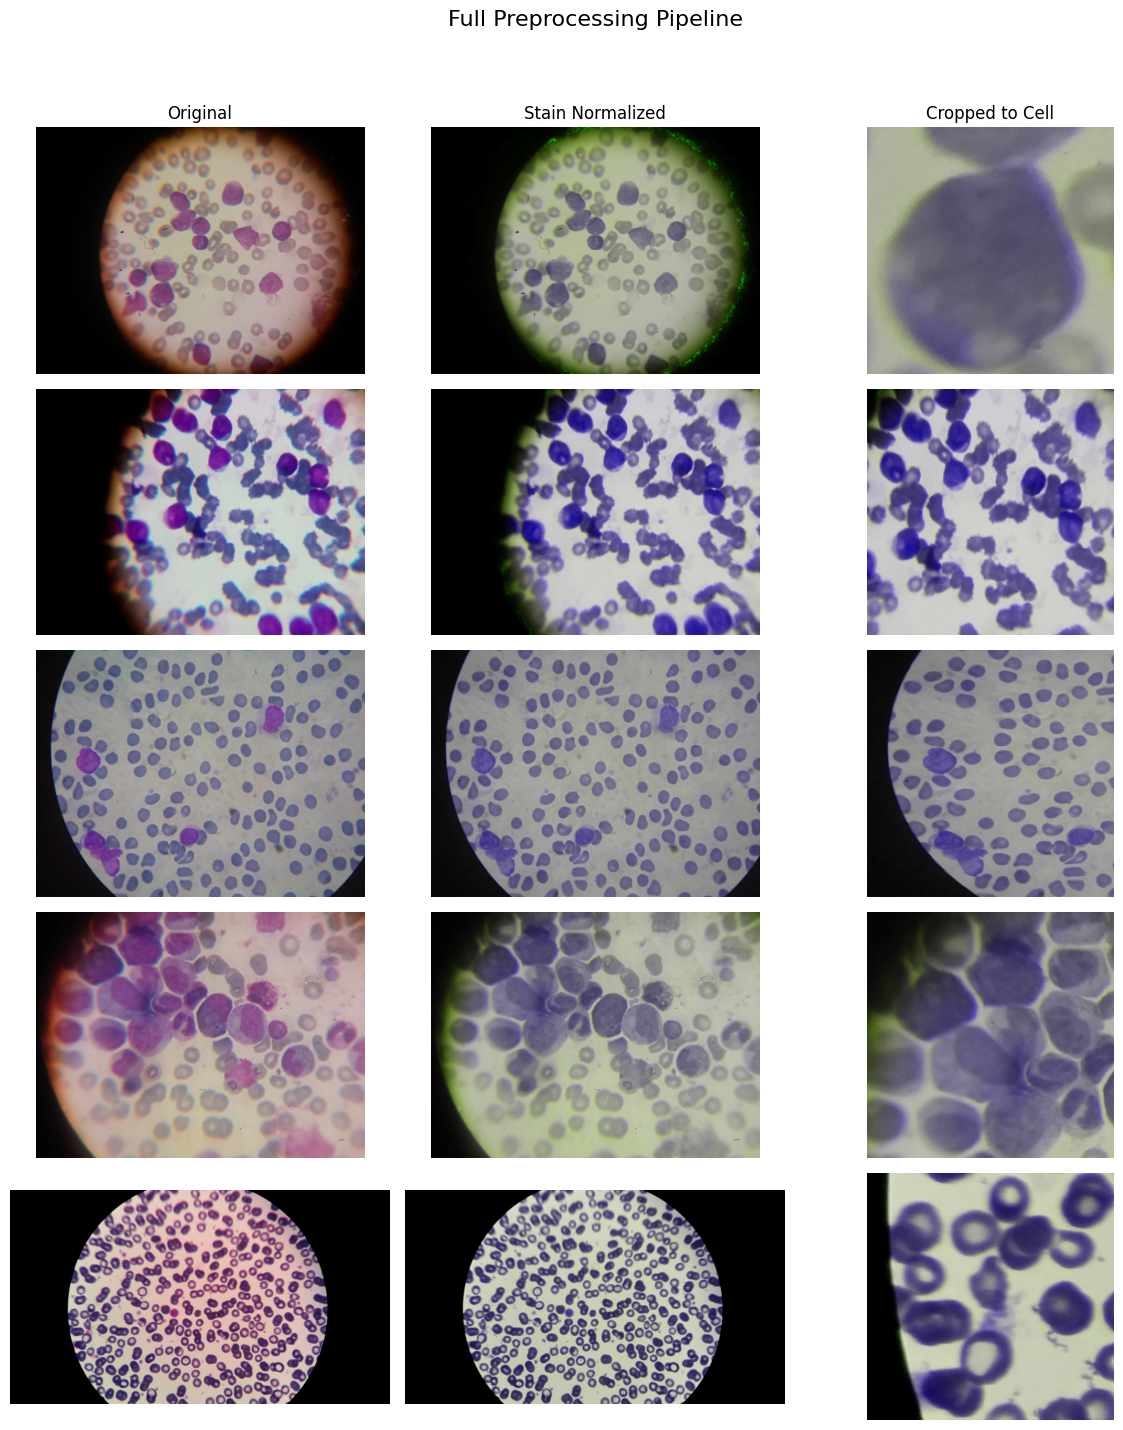

In [8]:
# ==============================================================================
# VISUALIZATION: Show the Full Preprocessing Pipeline
# ==============================================================================
print("Displaying the full preprocessing pipeline: Original -> Stain Normalized -> Cropped to Cell")

# Get the list of class subdirectories
class_labels = sorted(os.listdir(TRAIN_PATH))

# Create a figure with 3 columns to display the images
fig, axes = plt.subplots(len(class_labels), 3, figsize=(12, 15))
fig.suptitle('Full Preprocessing Pipeline', fontsize=16)

# Set the titles for each column
axes[0, 0].set_title('Original', fontsize=12)
axes[0, 1].set_title('Stain Normalized', fontsize=12)
axes[0, 2].set_title('Cropped to Cell', fontsize=12)

for i, label in enumerate(class_labels):
    # Construct path to the class directory
    class_path = os.path.join(TRAIN_PATH, label)
    sample_image_name = os.listdir(class_path)[0]
    sample_image_path = os.path.join(class_path, sample_image_name)
    
    # Load the original image at its native resolution
    original_img = image.load_img(sample_image_path)
    original_img_array = image.img_to_array(original_img).astype(np.uint8)
    
    # --- Step 1: Apply Stain Normalization ---
    stain_normalized_img = normalize_stain(original_img_array, TARGET_STAIN_VECTORS)

    # --- Step 2: Apply the new Contour-based Cropping ---
    cropped_cell_img = crop_to_largest_cell_contour(stain_normalized_img)

    # Plot the original image
    axes[i, 0].imshow(original_img)
    axes[i, 0].set_ylabel(label, fontsize=12, rotation=0, labelpad=40, ha='right')
    axes[i, 0].axis('off')
    
    # Plot the stain-normalized image
    axes[i, 1].imshow(stain_normalized_img)
    axes[i, 1].axis('off')

    # Plot the final cropped cell image
    axes[i, 2].imshow(cropped_cell_img)
    axes[i, 2].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [9]:
base_model = MobileNetV2(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

# Freeze the layers of the base model
for layer in base_model.layers:
    layer.trainable = False

# Add custom classification layers on top
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
prediction = Dense(len(class_labels), activation='softmax')(x)

# Create the final model
model = Model(inputs=base_model.input, outputs=prediction)

# Compile the model
model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  metrics=['accuracy']
)

model.summary()

I0000 00:00:1760148586.560110   19016 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4149 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 3,574,853 (13.64 MB)

 Trainable params: 1,316,869 (5.02 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
history = model.fit(
  training_set,
  validation_data=validation_set,
  epochs=10, # You can start with 25 and increase if needed
  steps_per_epoch=len(training_set),
  validation_steps=len(validation_set)
)
print("Model training complete.")

/run/media/Saksham/Saksham/Code/Projects/Leukemia/Imaging/imagingenv/lib/python3.13/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


2025-10-11 08:21:35.001630: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f483c002d30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-10-11 08:21:35.001650: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6
2025-10-11 08:21:35.146690: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-10-11 08:21:36.062539: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91301
2025-10-11 08:21:36.350089: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2025-10-11 08:21:38.

 11/375 ━━━━━━━━━━━━━━━━━━━━ 10:56 2s/step - accuracy: 0.3729 - loss: 1.6673

KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

# --- Detailed Evaluation on Test Set ---
print("\nEvaluating on the test set...")
# Make predictions
y_pred_probs = model.predict(test_set, steps=len(test_set))
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_set.classes

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

# Confusion Matrix
print("\nConfusion Matrix:\n")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
model.save('leukemia_detector_with_stain_normalization.h5')
print("\nModel saved successfully as 'leukemia_detector_with_stain_normalization.h5'")